# 🛒 E-Commerce Customer Churn Analysis & Prediction Dashboard.

**Dataset:** 6,000 customers · 14 features · Binary churn target  
**Goal:** Clean → Preprocess → Visualise → Train ML models → Analytical Dashboard

---

## 1. Imports & Setup

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import FancyBboxPatch
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, accuracy_score,
    f1_score, precision_score, recall_score, ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

try:
    import plotly.graph_objects as go
    import plotly.express as px
    from plotly.subplots import make_subplots
    PLOTLY = True
    print('✅ Plotly available to use — interactive charts enabled')
except ImportError:
    PLOTLY = False
    print('⚠️  Plotly not installed now — using Matplotlib only')

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11,
                     'axes.titlesize': 13, 'axes.labelsize': 11})
PALETTE = {'churn': '#E63946', 'retain': '#457B9D', 'neutral': '#A8DADC'}
print('✅ Setup complete')

✅ Plotly available — interactive charts enabled
✅ Setup complete


## 2. Load Data

In [5]:
FEATURES_PATH = 'ecommerce_customer_features.csv'
TARGETS_PATH  = 'ecommerce_customer_targets.csv'

df_feat = pd.read_csv(FEATURES_PATH)
df_targ = pd.read_csv(TARGETS_PATH)

df = df_feat.merge(df_targ, on='Customer_ID', how='inner')

print(f'Dataset shape : {df.shape}')
print(f'Columns       : {list(df.columns)}')
df.head()

Dataset shape : (6000, 16)
Columns       : ['Customer_ID', 'account_age_months', 'avg_order_value', 'total_orders', 'days_since_last_purchase', 'discount_usage_rate', 'return_rate', 'customer_support_tickets', 'loyalty_member', 'browsing_frequency_per_week', 'cart_abandonment_rate', 'product_review_score_avg', 'engagement_score', 'satisfaction_score', 'price_sensitivity_index', 'churned']


,Customer_ID,account_age_months,avg_order_value,total_orders,days_since_last_purchase,discount_usage_rate,return_rate,customer_support_tickets,loyalty_member,browsing_frequency_per_week,cart_abandonment_rate,product_review_score_avg,engagement_score,satisfaction_score,price_sensitivity_index,churned
0,0520df14-712d-4c69-a0c5-95a2e7dfc1ff,46,164.96,12,17,0.243,0.1720,0,No,6.1,0.430,5.00,6.58,9.43,3.7,No
1,a4013b3f-0688-4096-a194-6074be8ffec8,3,39.09,4,5,0.591,0.0808,1,No,4.1,0.183,4.44,6.25,8.50,6.9,No
2,eb870f2c-ed3d-4a21-a8ac-273fae69ea4f,29,37.42,8,47,0.212,0.1424,0,No,1.2,0.426,3.87,3.32,8.40,4.3,No
3,a7433451-8ea9-428a-9d80-679c6963b39f,35,62.64,9,3,0.699,0.0128,0,No,3.8,0.730,4.75,6.42,9.71,7.5,No
4,43f81935-49e3-44d3-94d1-5c4715738988,39,113.03,1,7,0.382,0.0232,0,No,5.4,0.613,5.00,6.48,9.92,5.0,No


## 3. Data Cleaning & Quality Audit

In [ ]:
print('=== MISSING VALUES  ===')
missing = df.isnull().sum()
print(missing[missing > 0] if missing.any() else 'None — dataset is complete  ✅')

print('\n=== DUPLICATES  ===')
dupes = df.duplicated().sum()
print(f'{dupes} duplicate rows found')
if dupes:
    df.drop_duplicates(inplace=True)

print('\n=== DATA TYPES ===')
print(df.dtypes)

print('\n=== NUMERIC RANGES / OUTLIERS (IQR) ===')
num_cols = df.select_dtypes(include=np.number).columns.tolist()
for col in num_cols:
    Q1, Q3 = df[col].quantile(.25), df[col].quantile(.75)
    IQR = Q3 - Q1
    outliers = ((df[col] < Q1 - 1.5*IQR) | (df[col] > Q3 + 1.5*IQR)).sum()
    print(f'  {col:35s}: {outliers:4d} outliers   [{df[col].min():.2f} – {df[col].max():.2f}]')

=== MISSING VALUES ===
None — dataset is complete ✅

=== DUPLICATES ===
0 duplicate rows found

=== DATA TYPES ===
Customer_ID                        str
account_age_months               int64
avg_order_value                float64
total_orders                     int64
days_since_last_purchase         int64
discount_usage_rate            float64
return_rate                    float64
customer_support_tickets         int64
loyalty_member                     str
browsing_frequency_per_week    float64
cart_abandonment_rate          float64
product_review_score_avg       float64
engagement_score               float64
satisfaction_score             float64
price_sensitivity_index        float64
churned                            str
dtype: object

=== NUMERIC RANGES / OUTLIERS (IQR) ===
  account_age_months                 :    0 outliers   [1.00 – 60.00]
  avg_order_value                    :  278 outliers   [10.00 – 1006.53]
  total_orders                       :  186 outliers   [1.00 – 

## 4. Pre-processing & Feature Engineering

In [6]:
df['churn_flag'] = (df['churned'] == 'Yes').astype(int)

df['loyalty_encoded'] = (df['loyalty_member'] == 'Yes').astype(int)

df['orders_per_month']       = df['total_orders'] / df['account_age_months'].replace(0, 1)
df['revenue_per_order']      = df['avg_order_value']
df['recency_bucket']         = pd.cut(df['days_since_last_purchase'],
                                      bins=[0,7,30,90,999],
                                      labels=['Hot','Warm','Cold','Dormant'])
df['value_segment']          = pd.qcut(df['avg_order_value'], q=4,
                                        labels=['Low','Mid','High','Premium'])
df['engagement_x_satisfaction'] = df['engagement_score'] * df['satisfaction_score']
df['support_heavy']          = (df['customer_support_tickets'] >= 3).astype(int)

print('✅ Pre-processing complete.')
print(f' Final shape: {df.shape}')
print('\nChurn Distribution :')
print(df['churn_flag'].value_counts())
print(f'Churn Rate: {df["churn_flag"].mean()*100:.1f}%')

✅ Pre-processing complete.
 Final shape: (6000, 24)

Churn Distribution :
churn_flag
0    5071
1     929
Name: count, dtype: int64
Churn Rate: 15.5%


## 5. Exploratory Data Analysis — Overview

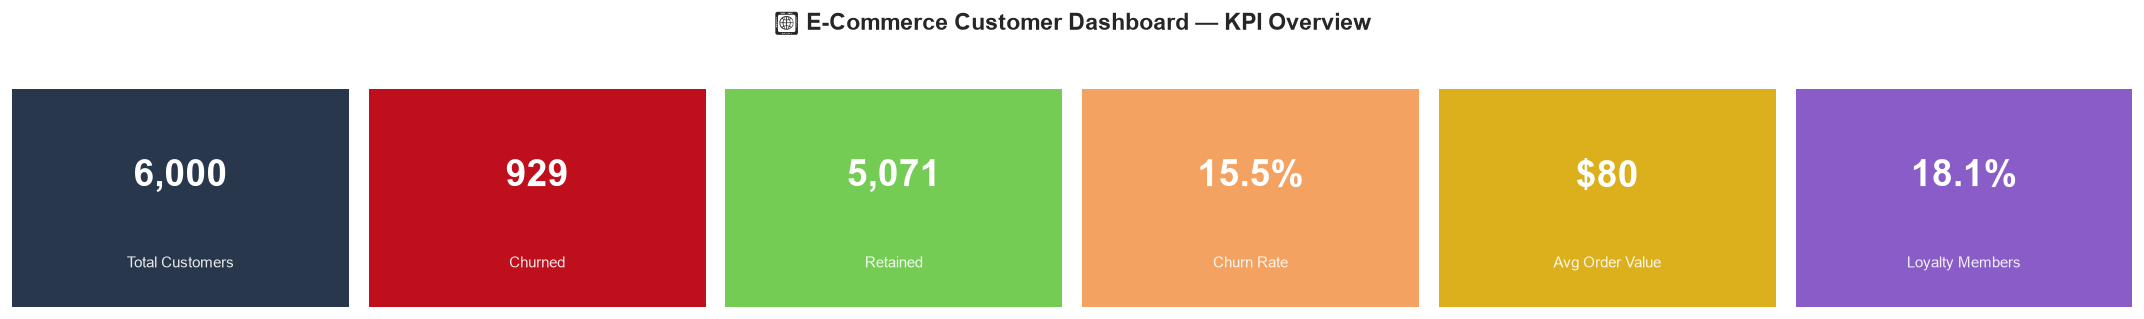

In [26]:
total      = len(df)
churned_n  = df['churn_flag'].sum()
retained_n = total - churned_n
churn_rate = churned_n / total * 100
avg_order  = df['avg_order_value'].mean()
loyalty_pct= df['loyalty_encoded'].mean() * 100

kpis = [
    ('Total Customers', f'{total:,}', "#28374B"),
    ('Churned',         f'{churned_n:,}', "#BF0E1C"),
    ('Retained',        f'{retained_n:,}', "#74CC54FF"),
    ('Churn Rate',      f'{churn_rate:.1f}%', '#F4A261'),
    ('Avg Order Value', f'${avg_order:.0f}', "#DCAF1D"),
    ('Loyalty Members', f'{loyalty_pct:.1f}%', "#895CC8"),
]

fig, axes = plt.subplots(1, 6, figsize=(18, 2.5))
for ax, (label, value, color) in zip(axes, kpis):
    ax.set_facecolor(color)
    ax.text(0.5, 0.6, value, ha='center', va='center',
            fontsize=22, fontweight='bold', color='white', transform=ax.transAxes)
    ax.text(0.5, 0.2, label, ha='center', va='center',
            fontsize=9, color='white', alpha=0.9, transform=ax.transAxes)
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values(): spine.set_visible(False)
plt.suptitle('📊 E-Commerce Customer Dashboard — KPI Overview', fontsize=14,
             fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

## 6. Target Variable Analysis

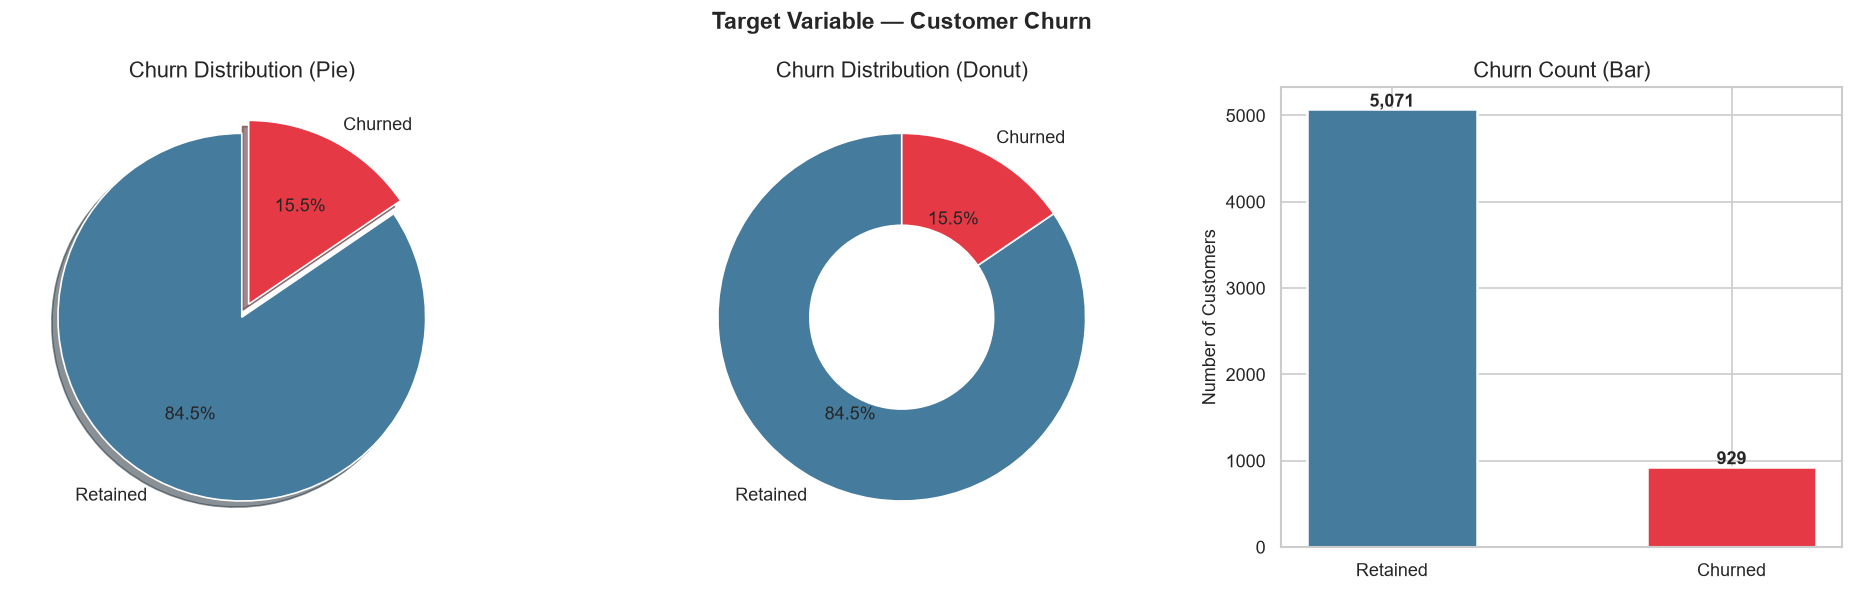

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

counts = df['churn_flag'].value_counts()
axes[0].pie(counts, labels=['Retained', 'Churned'],
            colors=[PALETTE['retain'], PALETTE['churn']],
            autopct='%1.1f%%', startangle=90,
            explode=(0, 0.08), shadow=True)
axes[0].set_title('Churn Distribution (Pie)')

axes[1].pie(counts, labels=['Retained', 'Churned'],
            colors=[PALETTE['retain'], PALETTE['churn']],
            autopct='%1.1f%%', startangle=90, wedgeprops={'width': 0.5})
axes[1].set_title('Churn Distribution (Donut)')

bars = axes[2].bar(['Retained', 'Churned'], counts.values,
                   color=[PALETTE['retain'], PALETTE['churn']],
                   edgecolor='white', linewidth=1.5, width=0.5)
for bar, val in zip(bars, counts.values):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
                 f'{val:,}', ha='center', fontweight='bold')
axes[2].set_title('Churn Count (Bar)')
axes[2].set_ylabel('Number of Customers')

plt.suptitle('Target Variable — Customer Churn', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 7. Numeric Feature Distributions

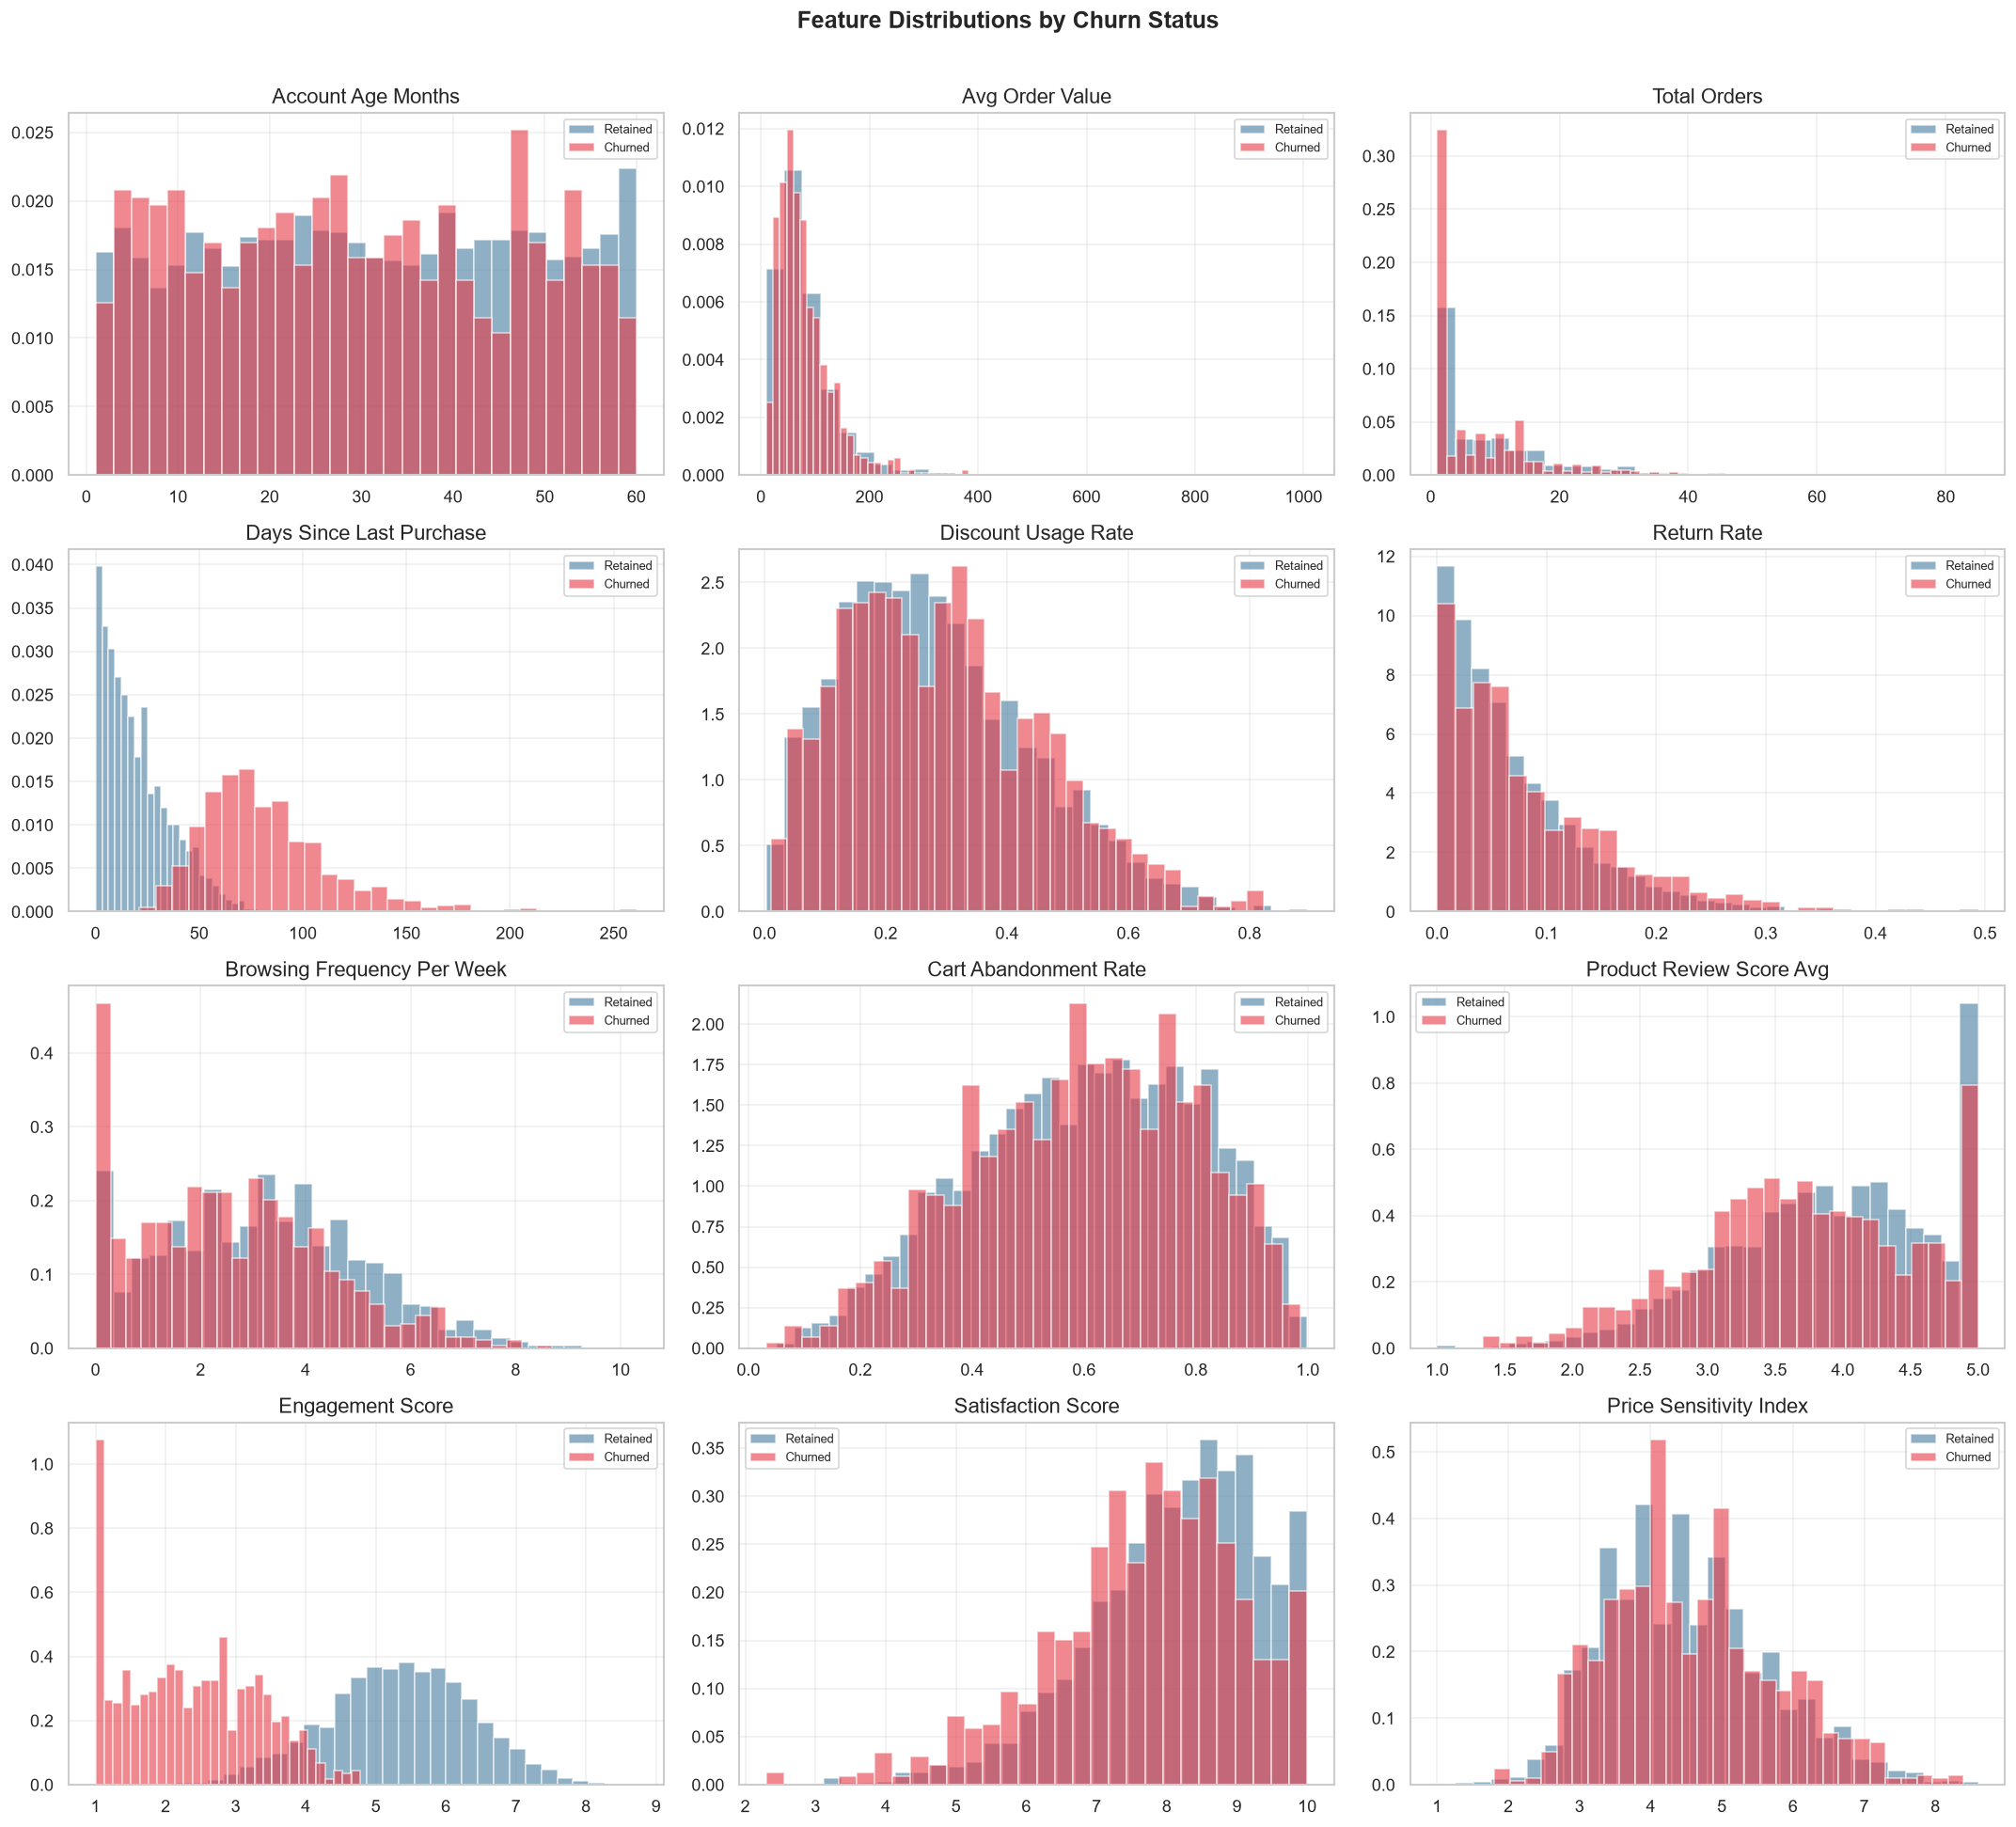

In [28]:
feat_cols = [
    'account_age_months','avg_order_value','total_orders',
    'days_since_last_purchase','discount_usage_rate','return_rate',
    'browsing_frequency_per_week','cart_abandonment_rate',
    'product_review_score_avg','engagement_score',
    'satisfaction_score','price_sensitivity_index'
]

fig, axes = plt.subplots(4, 3, figsize=(18, 16))
axes = axes.flatten()

for i, col in enumerate(feat_cols):
    ax = axes[i]
    for val, label, color in [(0,'Retained', PALETTE['retain']),
                               (1,'Churned',  PALETTE['churn'])]:
        subset = df[df['churn_flag'] == val][col]
        ax.hist(subset, bins=30, alpha=0.6, label=label, color=color, density=True)
    ax.set_title(col.replace('_', ' ').title())
    ax.set_xlabel('')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle('Feature Distributions by Churn Status', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## 8. Box Plots — Feature vs Churn

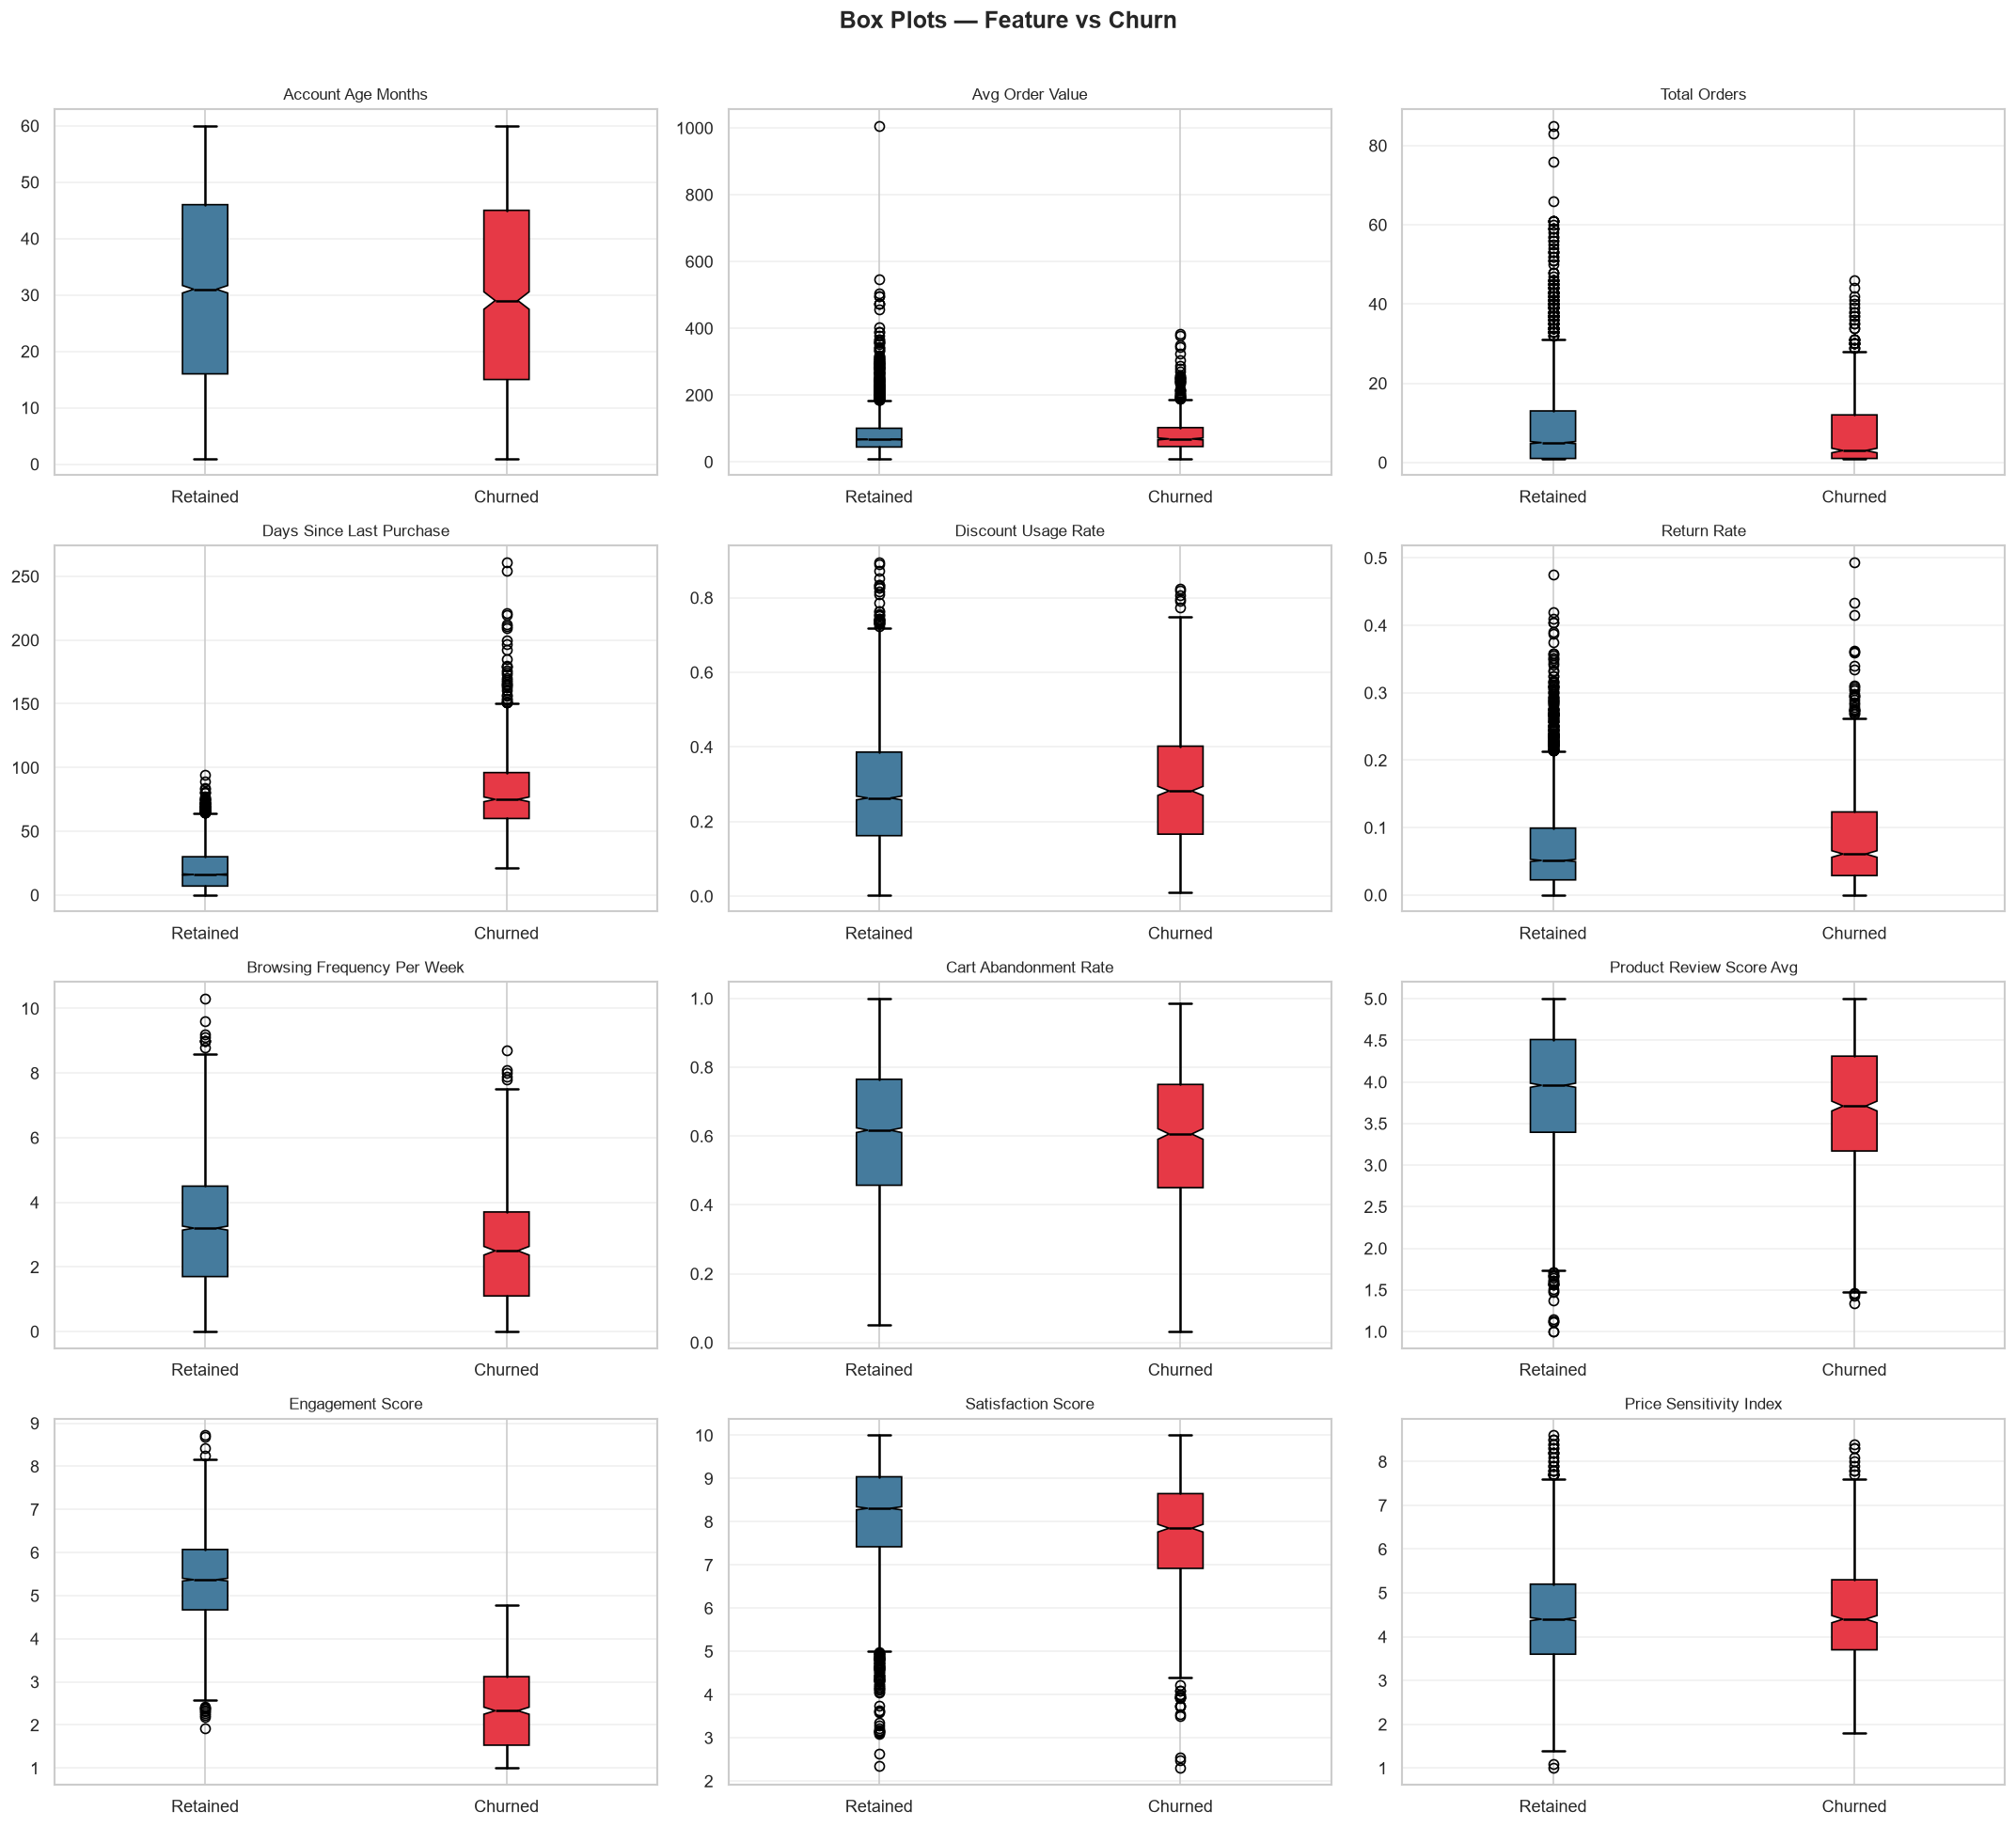

In [32]:
fig, axes = plt.subplots(4, 3, figsize=(18, 16))
axes = axes.flatten()

for i, col in enumerate(feat_cols):
    ax = axes[i]
    data_retain = df[df['churn_flag']==0][col]
    data_churn  = df[df['churn_flag']==1][col]
    bp = ax.boxplot([data_retain, data_churn],
                    patch_artist=True,
                    tick_labels=['Retained','Churned'],
                    notch=True)
    bp['boxes'][0].set_facecolor(PALETTE['retain'])
    bp['boxes'][1].set_facecolor(PALETTE['churn'])
    for element in ['whiskers','caps','medians']:
        for patch in bp[element]:
            patch.set_color('black')
            patch.set_linewidth(1.5)
    ax.set_title(col.replace('_', ' ').title(), fontsize=10)
    ax.grid(True, axis='y', alpha=0.3)

plt.suptitle('Box Plots — Feature vs Churn', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()